In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Set visualization style
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
# Load cleaned dataset
df = pd.read_csv("unemployment_cleaned.csv")

# Convert columns to the correct data types
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["estimated_unemployment_rate_(%)"] = pd.to_numeric(
    df["estimated_unemployment_rate_(%)"], errors="coerce"
)

# Remove rows missing essential values
df = df.dropna(
    subset=["date", "estimated_unemployment_rate_(%)"]
).copy()

# Sort observations chronologically
df = df.sort_values("date").reset_index(drop=True)

# Set visualization style
sns.set_theme(style="whitegrid")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Date range:", df["date"].min(), "to", df["date"].max())

display(df.head())

Dataset loaded successfully!
Rows: 740
Columns: 7
Date range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00


,region,date,frequency,estimated_unemployment_rate_(%),estimated_employed,estimated_labour_participation_rate_(%),area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Odisha,2019-05-31,Monthly,4.17,11155753.0,40.47,Rural
2,Odisha,2019-05-31,Monthly,2.95,2519582.0,41.26,Urban
3,Puducherry,2019-05-31,Monthly,0.00,172474.0,43.08,Rural
4,Puducherry,2019-05-31,Monthly,1.25,283905.0,35.71,Urban


In [6]:
# Create output folders
FIGURES_DIR = Path("figures")
REPORTS_DIR = Path("reports")

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

def save_figure(filename):
    """Save the current Matplotlib figure as a high-resolution PNG."""
    filepath = FIGURES_DIR / filename

    plt.savefig(
        filepath,
        dpi=300,
        bbox_inches="tight",
        facecolor="white"
    )

    print(f"Figure saved: {filepath}")

print("Output folders created successfully!")

Output folders created successfully!


In [8]:
# Descriptive Statistics
stats = df["estimated_unemployment_rate_(%)"].describe()

descriptive_statistics = pd.DataFrame({
    "Metric": [
        "Count",
        "Mean",
        "Median",
        "Standard Deviation",
        "Variance",
        "Minimum",
        "25th Percentile",
        "75th Percentile",
        "Maximum",
        "Range",
        "Skewness",
        "Kurtosis"
    ],
    "Value": [
        df["estimated_unemployment_rate_(%)"].count(),
        df["estimated_unemployment_rate_(%)"].mean(),
        df["estimated_unemployment_rate_(%)"].median(),
        df["estimated_unemployment_rate_(%)"].std(),
        df["estimated_unemployment_rate_(%)"].var(),
        df["estimated_unemployment_rate_(%)"].min(),
        df["estimated_unemployment_rate_(%)"].quantile(0.25),
        df["estimated_unemployment_rate_(%)"].quantile(0.75),
        df["estimated_unemployment_rate_(%)"].max(),
        df["estimated_unemployment_rate_(%)"].max() - df["estimated_unemployment_rate_(%)"].min(),
        df["estimated_unemployment_rate_(%)"].skew(),
        df["estimated_unemployment_rate_(%)"].kurt()
    ]
})

display(descriptive_statistics.round(3))

descriptive_statistics.to_csv(
    REPORTS_DIR / "descriptive_statistics.csv",
    index=False
)

,Metric,Value
0,Count,740.000
1,Mean,11.788
2,Median,8.350
3,Standard Deviation,10.721
4,Variance,114.946
5,Minimum,0.000
6,25th Percentile,4.658
7,75th Percentile,15.888
8,Maximum,76.740
9,Range,76.740


Figure saved: figures/01_unemployment_distribution.png


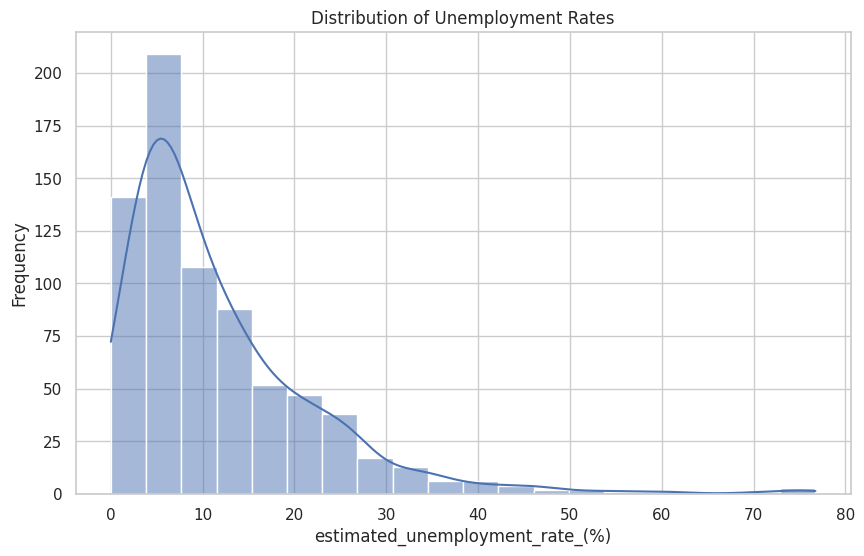

In [9]:
# Unemployment rate distribution
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="estimated_unemployment_rate_(%)",
    bins=20,
    kde=True
)

plt.title("Distribution of Unemployment Rates")
plt.xlabel("estimated_unemployment_rate_(%)")
plt.ylabel("Frequency")

save_figure("01_unemployment_distribution.png")
plt.show()
plt.close()

Figure saved: figures/02_unemployment_boxplot.png


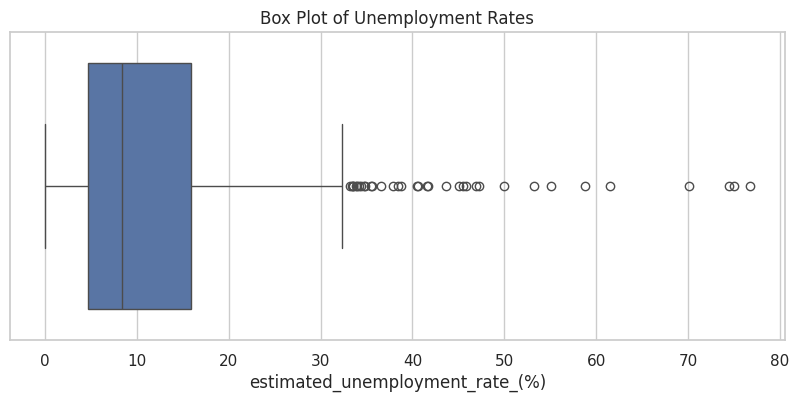

In [10]:
# Outlier
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["estimated_unemployment_rate_(%)"]
)

plt.title("Box Plot of Unemployment Rates")
plt.xlabel("estimated_unemployment_rate_(%)")

save_figure("02_unemployment_boxplot.png")
plt.show()
plt.close()

In [12]:
# Potential outlier using IQR Method
Q1 = df["estimated_unemployment_rate_(%)"].quantile(0.25)
Q3 = df["estimated_unemployment_rate_(%)"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_records = df[
    (df["estimated_unemployment_rate_(%)"] < lower_bound) |
    (df["estimated_unemployment_rate_(%)"] > upper_bound)
].copy()

print("Potential outliers:", len(outlier_records))
print("Lower boundary:", round(lower_bound, 3))
print("Upper boundary:", round(upper_bound, 3))

outlier_records.to_csv(
    REPORTS_DIR / "outlier_records.csv",
    index=False
)

display(outlier_records.head(10))

Potential outliers: 35
Lower boundary: -12.187
Upper boundary: 32.732


,region,date,frequency,estimated_unemployment_rate_(%),estimated_employed,estimated_labour_participation_rate_(%),area
42,Tripura,2019-05-31,Monthly,34.69,423127.0,69.50,Urban
165,Tripura,2019-08-31,Monthly,33.45,368977.0,59.07,Urban
266,Tripura,2019-09-30,Monthly,33.57,418043.0,66.90,Urban
405,Tripura,2019-12-31,Monthly,33.48,399427.0,63.41,Urban
481,Tripura,2020-01-31,Monthly,34.37,450155.0,72.26,Urban
512,Tripura,2020-02-29,Monthly,33.88,415339.0,66.04,Urban
588,Haryana,2020-04-30,Monthly,46.89,1606580.0,35.48,Urban
589,Haryana,2020-04-30,Monthly,41.61,4041050.0,49.85,Rural
597,Tripura,2020-04-30,Monthly,43.64,675083.0,52.63,Rural
613,Puducherry,2020-04-30,Monthly,74.51,49420.0,46.79,Rural


Figure saved: figures/03_unemployment_trend.png


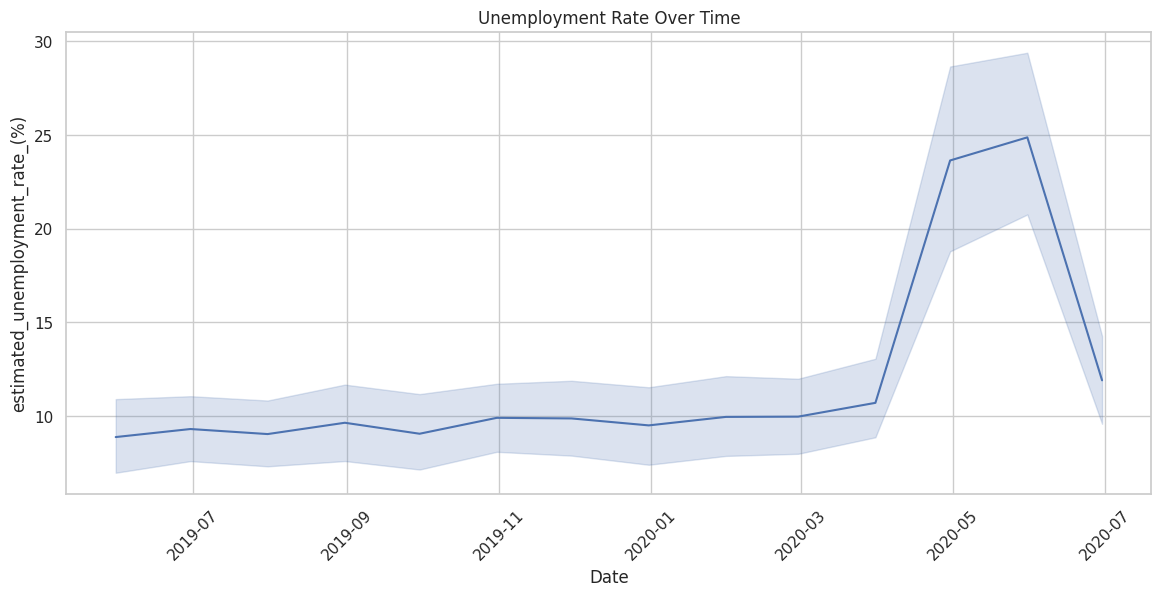

In [16]:
# Unemployment trend over time
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=df,
    x="date",
    y="estimated_unemployment_rate_(%)"
)

plt.title("Unemployment Rate Over Time")
plt.xlabel("Date")
plt.ylabel("estimated_unemployment_rate_(%)")
plt.xticks(rotation=45)

save_figure("03_unemployment_trend.png")
plt.show()
plt.close()

In [27]:
# Average unemployment by year
df["year"] = df["date"].dt.year

yearly_summary = (
    df.groupby("year")["estimated_unemployment_rate_(%)"]
    .agg(["mean", "median", "min", "max", "count"])
    .reset_index()
)

yearly_summary.columns = [
    "year", "mean", "median", "minimum", "maximum", "count"
]

display(yearly_summary.round(3))

yearly_summary.to_csv(
    REPORTS_DIR / "yearly_summary.csv",
    index=False
)

,year,mean,median,minimum,maximum,count
0,2019,9.399,7.115,0.0,34.69,430
1,2020,15.102,10.790,0.0,76.74,310


Figure saved: figures/04_yearly_average.png


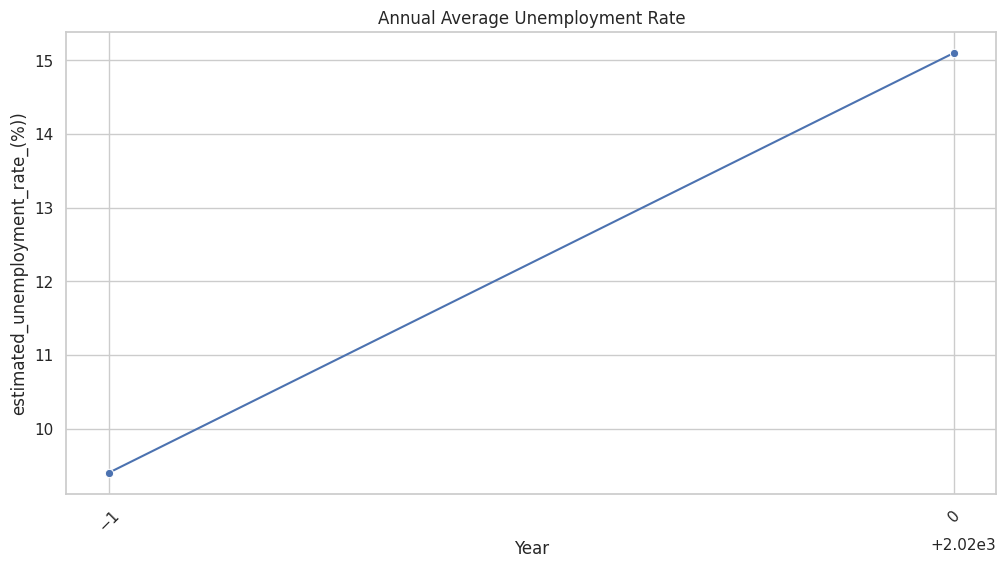

In [28]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=yearly_summary,
    x="year",
    y="mean",
    marker="o"
)

plt.title("Annual Average Unemployment Rate")
plt.xlabel("Year")
plt.ylabel("estimated_unemployment_rate_(%))")
plt.xticks(yearly_summary["year"], rotation=45)

save_figure("04_yearly_average.png")
plt.show()
plt.close()

Figure saved: figures/05_unemployment_changes.png


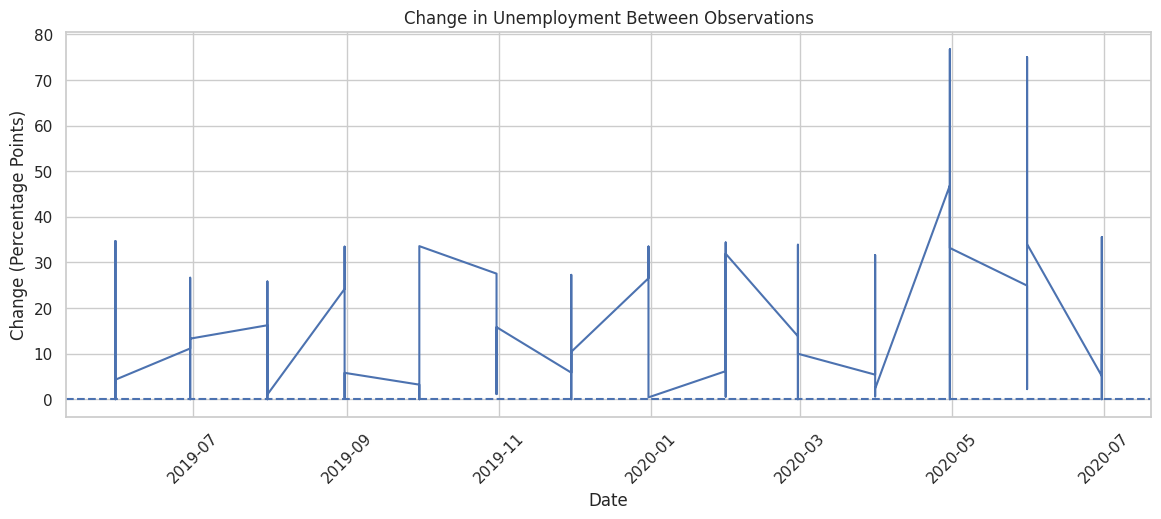

In [29]:
# Changes between observations
df["unemployment_change"] = (
    df["estimated_unemployment_rate_(%)"].diff()
)

plt.figure(figsize=(14, 5))

plt.plot(
    df["date"],
    df["estimated_unemployment_rate_(%)"]
)

plt.axhline(0, linestyle="--")

plt.title("Change in Unemployment Between Observations")
plt.xlabel("Date")
plt.ylabel("Change (Percentage Points)")
plt.xticks(rotation=45)

save_figure("05_unemployment_changes.png")
plt.show()
plt.close()

In [30]:
# Monthly Pattern
df["month"] = df["date"].dt.month

monthly_summary = (
    df.groupby("month")["estimated_unemployment_rate_(%)"]
    .agg(["mean", "median", "count"])
    .reset_index()
)

monthly_summary["month_name"] = (
    pd.to_datetime(
        monthly_summary["month"],
        format="%m"
    ).dt.month_name()
)

display(monthly_summary.round(3))

monthly_summary.to_csv(
    REPORTS_DIR / "monthly_summary.csv",
    index=False
)

,month,mean,median,count,month_name
0,1,9.951,6.790,53,January
1,2,9.965,7.550,53,February
2,3,10.701,8.530,52,March
3,4,23.642,18.320,51,April
4,5,16.646,12.960,105,May
5,6,10.553,9.165,104,June
6,7,9.034,7.160,54,July
7,8,9.638,7.270,53,August
8,9,9.052,6.240,52,September
9,10,9.901,7.290,55,October


Figure saved: figures/06_monthly_patterns.png


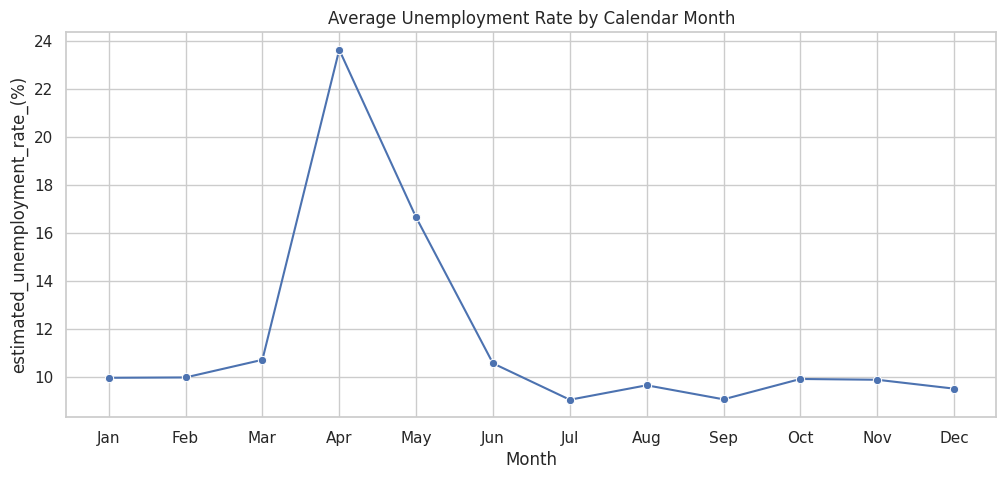

In [33]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=monthly_summary,
    x="month",
    y="mean",
    marker="o"
)

plt.xticks(
    range(1, 13),
    ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
     "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
)

plt.title("Average Unemployment Rate by Calendar Month")
plt.xlabel("Month")
plt.ylabel("estimated_unemployment_rate_(%)")

save_figure("06_monthly_patterns.png")
plt.show()
plt.close()

Figure saved: figures/07_missing_values.png


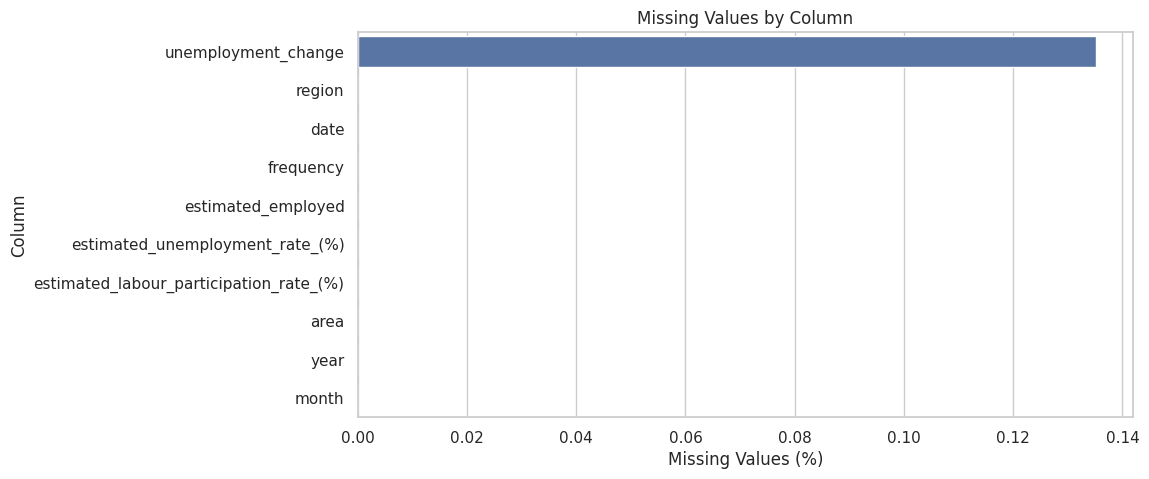

In [34]:
# Missing-value
plt.figure(figsize=(10, 5))

missing_percent = (
    df.isnull().mean() * 100
).sort_values(ascending=False)

sns.barplot(
    x=missing_percent.values,
    y=missing_percent.index
)

plt.title("Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Column")

save_figure("07_missing_values.png")
plt.show()
plt.close()

In [35]:
# Export all figure and save into zip file
import zipfile

zip_path = Path("unemployment_eda_outputs.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zipf:
    for folder in [FIGURES_DIR, REPORTS_DIR]:
        for file in folder.rglob("*"):
            if file.is_file():
                zipf.write(file, file.as_posix())

print(f"EDA outputs packaged into: {zip_path}")

EDA outputs packaged into: unemployment_eda_outputs.zip


In [36]:
from google.colab import files

files.download("unemployment_eda_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>